# Práctica 4 de manifold learning

Inteligencia de Negocio · 2026

**Nombre y apellidos:**

Completa las celdas de código y los comentarios siguiendo el enunciado. La carga de datos, el escalado y las funciones para dibujar los mapas y los diagramas de Shepard ya están preparados.

Coloca este notebook y `4000datosSimuladosEnergia.xlsx` en la misma carpeta. Para la parte opcional de Sammon necesitarás también `sammon.py`. Las dependencias figuran en `requirements.txt`.

## Preparación de los datos

`X` contiene los diez atributos estandarizados de los 4000 contratos. Utiliza esta misma matriz en todos los métodos. `perfiles` se reserva para colorear los mapas.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import LocallyLinearEmbedding, MDS, Isomap, TSNE
from umap import UMAP

c:\Users\nicom\Desktop\Mierda\Practicas-InteligenciaDelNegocio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
datos = pd.read_excel("4000datosSimuladosEnergia.xlsx")
perfiles = datos["Perfil de contrato"]
atributos = datos.drop(columns="Perfil de contrato")

X = StandardScaler().fit_transform(atributos)
print("Contratos:", X.shape[0], "  Atributos de entrada:", X.shape[1])
atributos.head()

Contratos: 4000   Atributos de entrada: 10


ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (c:\Users\nicom\Desktop\Mierda\Practicas-InteligenciaDelNegocio\.venv\Lib\site-packages\pandas\io\formats\format.py)

   Antiguedad Contrato  Superficie domicilio  Potencia eléctrica contratada  \
0             6.485366            124.091151                       0.522291   
1             4.129870            115.942734                       0.515981   
2             4.971928             54.312534                       3.492675   
3             2.822133            119.851951                       3.754567   
4             1.213862             70.074636                       1.889477   

   Consumo electricidad punta  Consumo electricidad llano  \
0                    1.012331                    4.535023   
1                    2.156610                    4.779190   
2                    1.357867                    1.795412   
3                    4.577912                    1.644414   
4                    3.467942                    3.928106   

   Consumo electricidad valle  Consumo gas medio  Generación fotovoltaica  \
0                    1.791129           2.295508                 0.500708   
1   

### Función para dibujar los mapas

Usa `dibuja_mapa(mapa, "Título")` cuando hayas obtenido las dos coordenadas de cada contrato. La función mantiene los mismos colores para los perfiles y la misma escala en los dos ejes.

In [6]:
colores = {perfil: plt.get_cmap("tab10")(i)
           for i, perfil in enumerate(sorted(perfiles.unique()))}

def dibuja_mapa(mapa, titulo):
    fig, ax = plt.subplots(figsize=(7, 6))
    for perfil, color in colores.items():
        seleccion = perfiles.to_numpy() == perfil
        ax.scatter(mapa[seleccion, 0], mapa[seleccion, 1],
                   s=5, color=color, label=str(perfil), alpha=0.75)
    ax.set_title(titulo)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xlabel("Coordenada 1")
    ax.set_ylabel("Coordenada 2")
    ax.legend(title="Perfil de contrato")
    fig.tight_layout()
    plt.show()

### Diagramas de Shepard

Usa `dibuja_shepard(X, mapa, "Título")` para acompañar cada mapa. El eje horizontal representa las distancias euclídeas entre los contratos estandarizados y el vertical las distancias en el mapa. La función ajusta una sola escala global para comparar mapas con unidades distintas.

Cuanto más se concentren los pares alrededor de la diagonal, mejor se conservan esas distancias. Los pares por debajo de la diagonal se han acercado y los situados por encima se han separado, después del ajuste de escala. El color indica el número de pares en cada zona.

Este diagnóstico complementa la distribución de los perfiles. Se refiere a las distancias euclídeas de entrada; no mide por sí solo la calidad de las vecindades ni la conservación de distancias geodésicas.

In [7]:
from scipy.spatial.distance import pdist

def dibuja_shepard(X, mapa, titulo):
    distancias_entrada = pdist(X)
    distancias_mapa = pdist(mapa)
    denominador = np.dot(distancias_mapa, distancias_mapa)
    if denominador == 0:
        raise ValueError("El mapa tiene todas sus coordenadas iguales")
    escala = np.dot(distancias_entrada, distancias_mapa) / denominador
    distancias_mapa = escala * distancias_mapa

    fig, ax = plt.subplots(figsize=(7, 6))
    densidad = ax.hexbin(distancias_entrada, distancias_mapa,
                         gridsize=65, bins="log", mincnt=1, cmap="Blues")
    limite = max(distancias_entrada.max(), distancias_mapa.max())
    ax.plot([0, limite], [0, limite], "k--", linewidth=1)
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Distancia entre contratos estandarizados")
    ax.set_ylabel("Distancia en el mapa con escala ajustada")
    ax.set_title("Shepard · " + titulo)
    fig.colorbar(densidad, ax=ax, label="Número de pares")
    fig.tight_layout()
    plt.show()

## Parte obligatoria

### 1 PCA

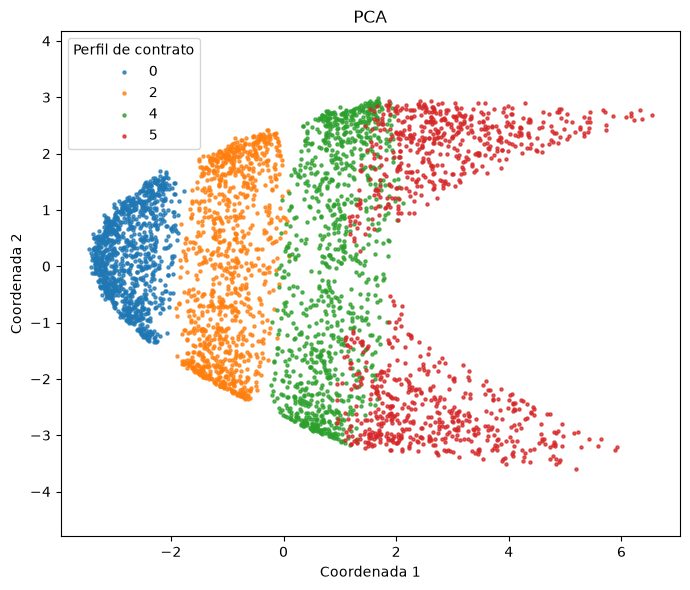

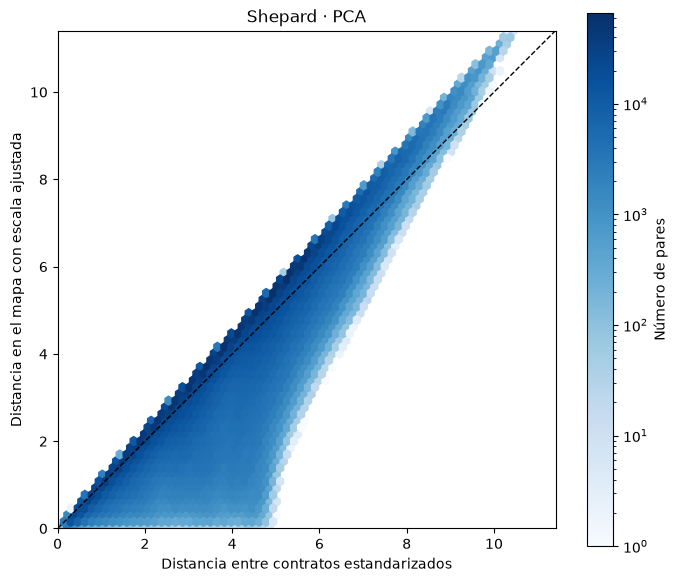

In [8]:
# Crea un modelo PCA con dos componentes y aplícalo a X.
pca = PCA(n_components=2)
mapa_pca = pca.fit_transform(X)
# Guarda el resultado en mapa_pca y dibújalo con dibuja_mapa.
dibuja_mapa(mapa_pca, "PCA")
# Añade también dibuja_shepard(X, mapa_pca, "PCA").
dibuja_shepard(X, mapa_pca, "PCA")


### 2 LLE con LTSA

Prueba distintos números de vecinos y compara los mapas.

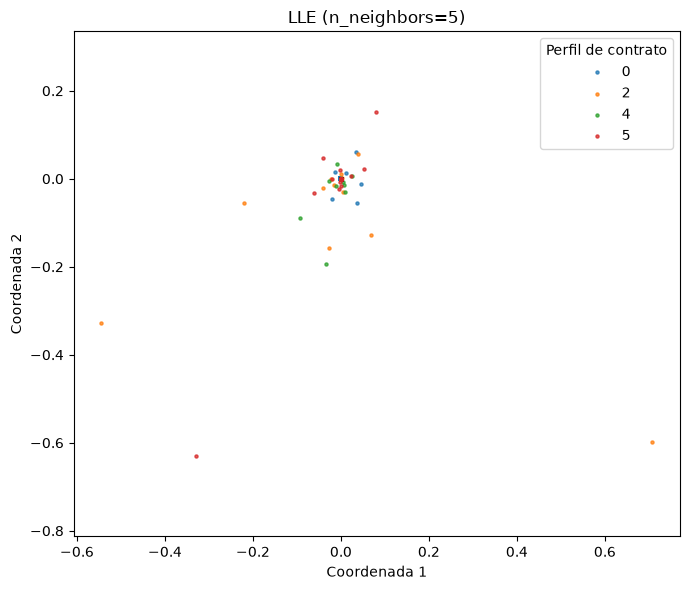

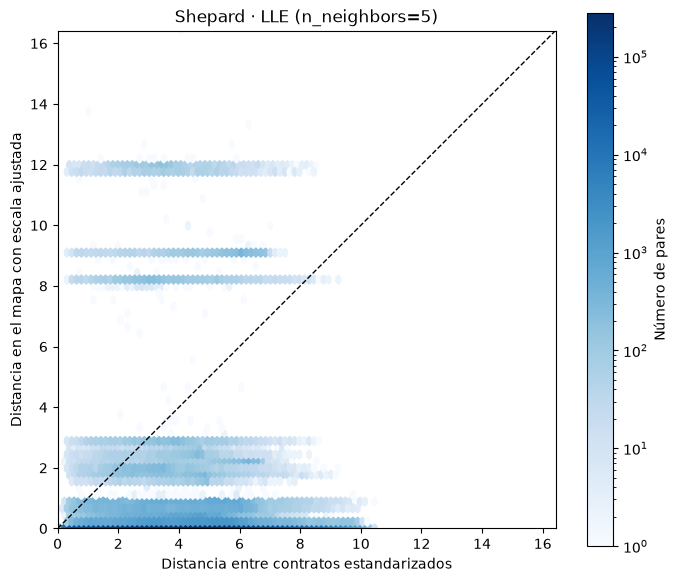

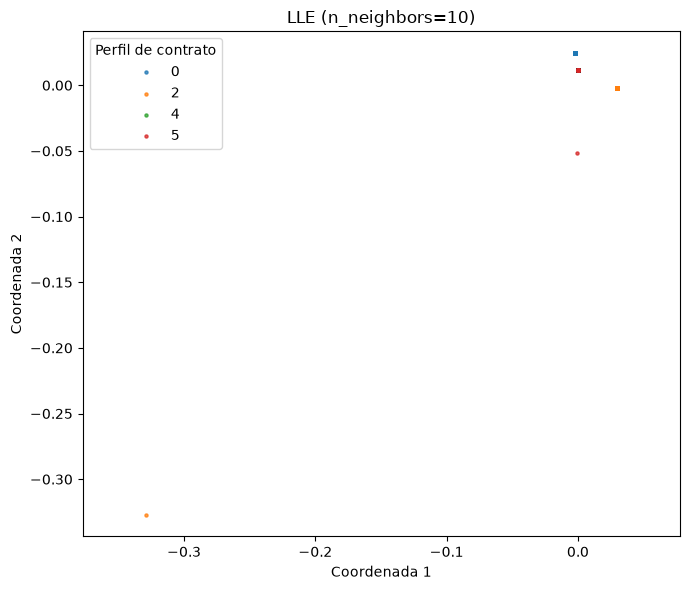

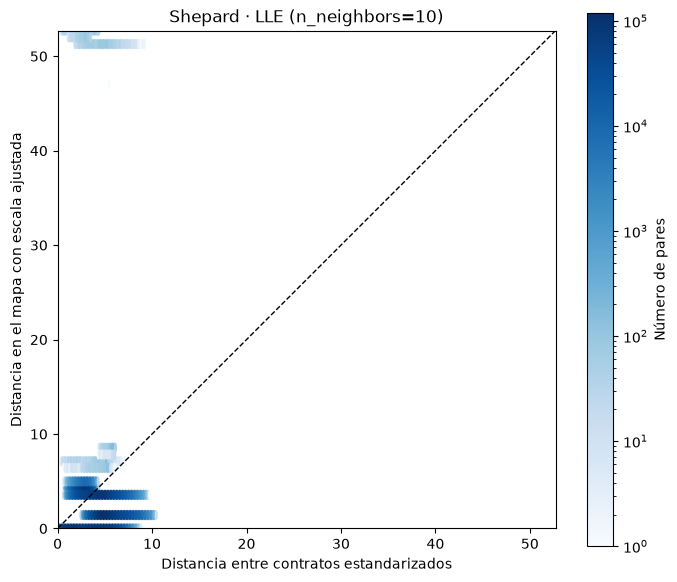

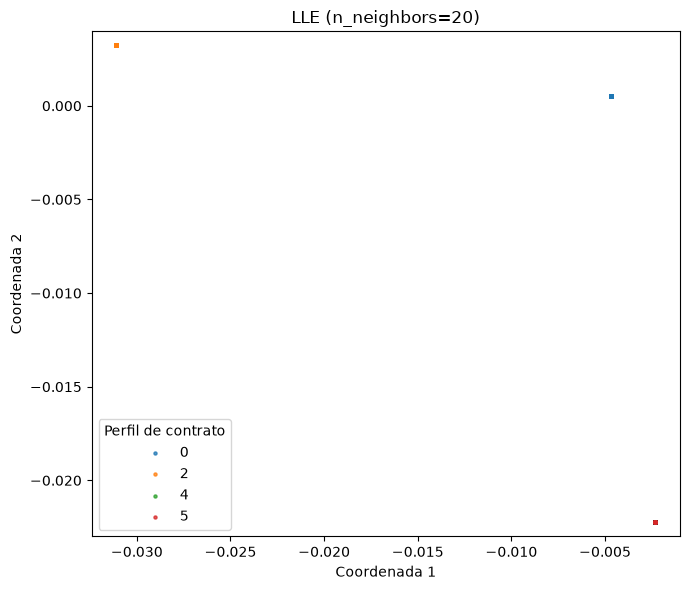

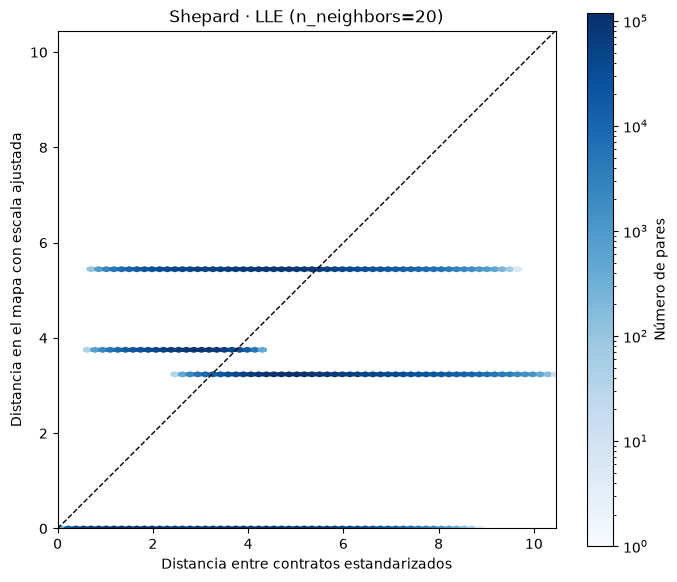

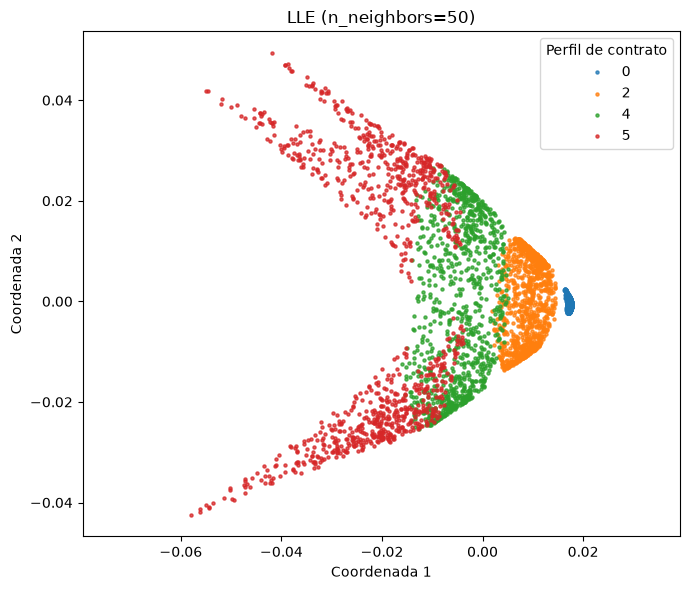

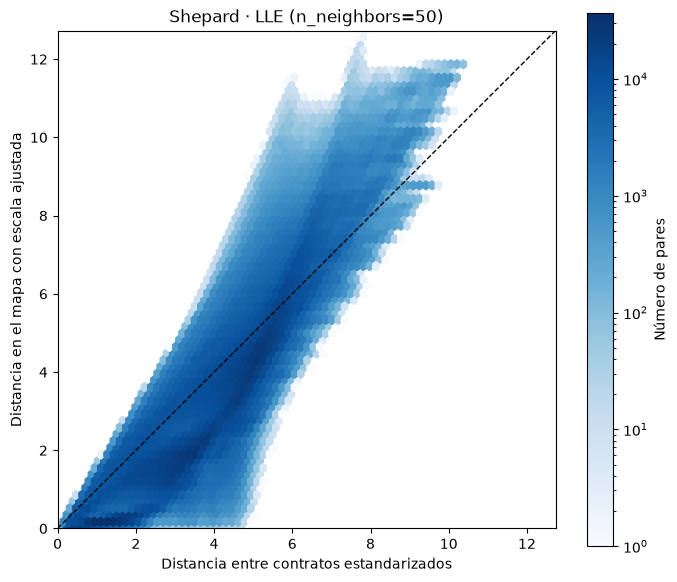

In [11]:
# Utiliza LocallyLinearEmbedding con method="ltsa" y dos componentes.
LocallyLinearEmbedding_ltsa = LocallyLinearEmbedding(n_components=2, method="ltsa", eigen_solver="dense")
# Cambia n_neighbors y dibuja los mapas obtenidos a partir de X.
n_neighbors_values = [5, 10, 20, 50]
for n_neighbors in n_neighbors_values:
    LocallyLinearEmbedding_ltsa.set_params(n_neighbors=n_neighbors)
    mapa_lle = LocallyLinearEmbedding_ltsa.fit_transform(X)
    dibuja_mapa(mapa_lle, f"LLE (n_neighbors={n_neighbors})")
    dibuja_shepard(X, mapa_lle, f"LLE (n_neighbors={n_neighbors})")
# Acompaña cada mapa de su diagrama con dibuja_shepard.


### 3 MDS mediante SMACOF

c:\Users\nicom\Desktop\Mierda\Practicas-InteligenciaDelNegocio\.venv\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
c:\Users\nicom\Desktop\Mierda\Practicas-InteligenciaDelNegocio\.venv\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


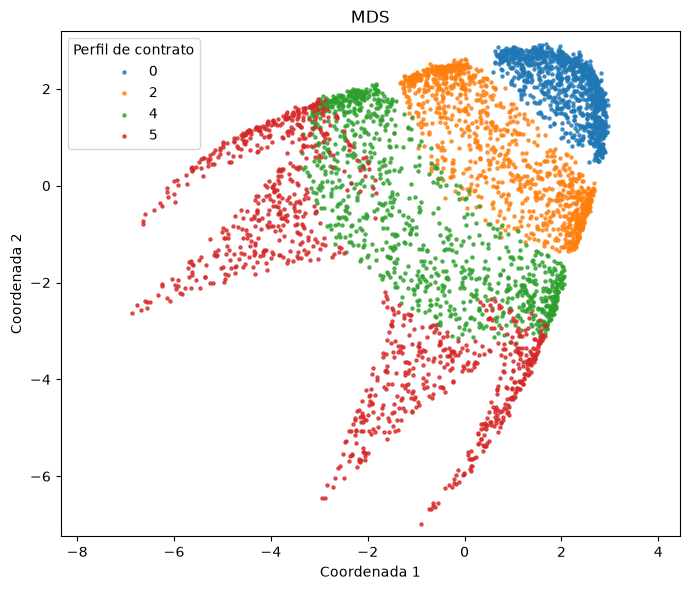

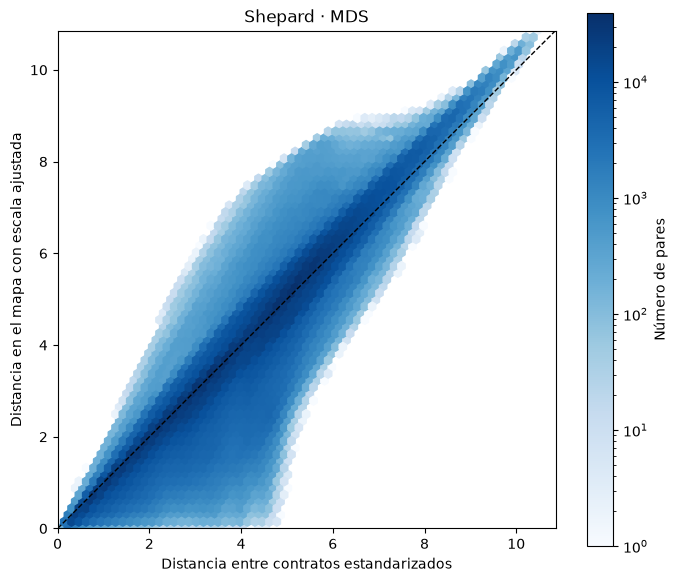

In [12]:
# Utiliza MDS de scikit-learn para obtener dos coordenadas a partir de X.
MDS_model = MDS(n_components=2, dissimilarity="euclidean", random_state=42)
# Guarda el resultado en mapa_mds y dibújalo.
mapa_mds = MDS_model.fit_transform(X)
dibuja_mapa(mapa_mds, "MDS")

# Añade su diagrama con dibuja_shepard(X, mapa, "Título").
dibuja_shepard(X, mapa_mds, "MDS")


### 4 UMAP

c:\Users\nicom\Desktop\Mierda\Practicas-InteligenciaDelNegocio\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


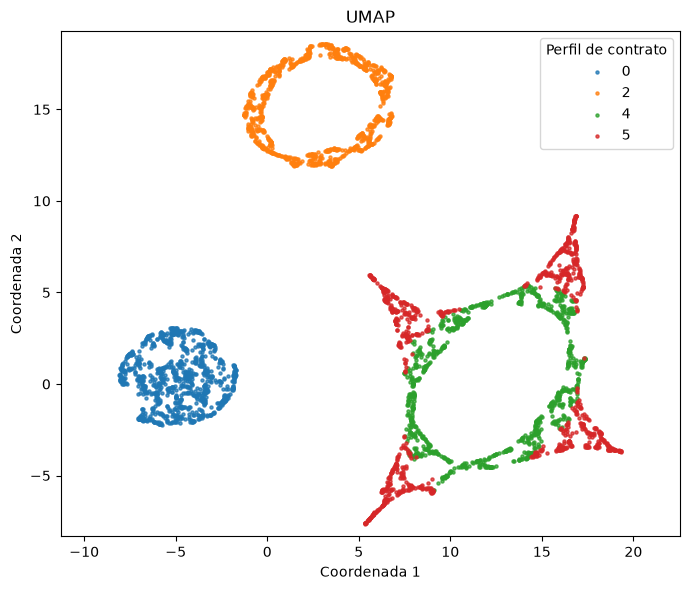

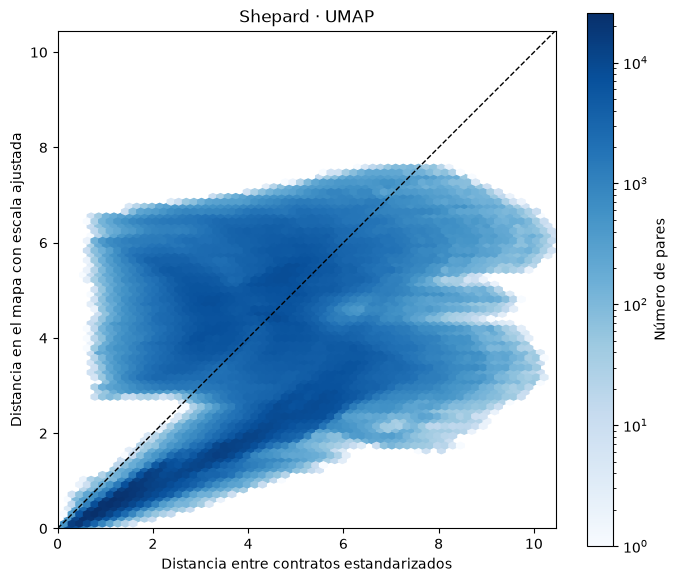

In [13]:
# Crea un modelo UMAP con dos componentes y aplícalo a X.
UMAP_model = UMAP(n_components=2, random_state=42)
# Guarda el resultado en mapa_umap y dibújalo.
mapa_umap = UMAP_model.fit_transform(X)
dibuja_mapa(mapa_umap, "UMAP")

# Añade su diagrama con dibuja_shepard(X, mapa, "Título").
dibuja_shepard(X, mapa_umap, "UMAP")


### Comparación de la parte obligatoria

¿Qué número de vecinos elegirías para LTSA? ¿Qué método ofrece la representación más informativa de los contratos? Justifica tus respuestas a partir de los mapas y de sus diagramas de Shepard. Distingue entre separar los perfiles y conservar las distancias euclídeas.

## Parte opcional 1

### 1 Sammon

Puedes utilizar directamente la función suministrada en `sammon.py`. Recibe una matriz de distancias y un mapa inicial `Y0`. Devuelve el mapa y el historial del coste.

In [ ]:
from scipy.spatial.distance import pdist, squareform
from sammon import sammon

# Obtén la matriz de distancias euclídeas entre las filas de X con
# squareform(pdist(X)). Aplica sammon usando mapa_pca como Y0.
Squareform_distances = squareform(pdist(X))
mapa_sammon, error = sammon(Squareform_distances, Y=mapa_pca, niter=100, tol=1e-9)
# Dibuja el mapa resultante y su diagrama de Shepard.
dibuja_mapa(mapa_sammon, "Sammon")
dibuja_shepard(X, mapa_sammon, "Sammon")

### 2 Isomap

In [ ]:
# Aplica Isomap con dos componentes a X y dibuja el mapa.

# Añade su diagrama con dibuja_shepard(X, mapa, "Título").


### 3 t-SNE

In [ ]:
# Aplica TSNE con dos componentes a X y dibuja el mapa.

# Añade su diagrama con dibuja_shepard(X, mapa, "Título").


### Comparación de la parte opcional 1

¿Alguno de estos métodos mejora la representación obtenida en la parte obligatoria?

Apoya la discusión también en los diagramas de Shepard y en lo que intenta conservar cada método.


## Parte opcional 2

### Kernel PCA con RBF

In [ ]:
# Utiliza KernelPCA con kernel="rbf" y dos componentes.
# Ajusta los parámetros que necesites y dibuja el mapa obtenido a partir de X.

# Añade su diagrama con dibuja_shepard(X, mapa, "Título").


### Kernel PCA con sigmoide

In [ ]:
# Utiliza KernelPCA con kernel="sigmoid" y dos componentes.
# Ajusta los parámetros que necesites y dibuja el mapa obtenido a partir de X.

# Añade su diagrama con dibuja_shepard(X, mapa, "Título").


### Comparación de la parte opcional 2

Comenta los resultados y si alguno de los dos kernels mejora los mapas anteriores.

Apoya la discusión también en los diagramas de Shepard y en lo que intenta conservar cada método.
